# Initial Tasks

## Installation of Modules

In [1]:
# ============================================================
# 1. DATA MANIPULATION
# ============================================================
import pandas as pd
import numpy as np


# ============================================================
# 2. DEEP LEARNING: TENSORFLOW AND KERAS
# ============================================================
import tensorflow as tf
from tensorflow import keras

from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import *
from tensorflow.keras.optimizers import (
    Adam,
    RMSprop,
    SGD,
    Adagrad,
    Adadelta,
    Adamax,
    Nadam
)

# Model training callbacks
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)


# ============================================================
# 3. HYPERPARAMETER TUNING
# ============================================================
import keras_tuner as kt


# ============================================================
# 4. MODEL EVALUATION METRICS
# ============================================================
from sklearn.metrics import (
    accuracy_score,
    r2_score,
    mean_squared_error,
    mean_absolute_error
)


# ============================================================
# 5. DATA PREPROCESSING AND SPLITTING
# ============================================================
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    RobustScaler,
    MinMaxScaler,
    StandardScaler
)


# ============================================================
# 6. DIMENSIONALITY REDUCTION
# ============================================================
from sklearn.decomposition import PCA


# ============================================================
# 7. MISSING DATA IMPUTATION
# ============================================================
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

# Estimators used to estimate missing values
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression


# ============================================================
# 8. VISUALIZATION
# ============================================================
import matplotlib.pyplot as plt


# ============================================================
# 9. OPTIMIZATION FOR MOVING HORIZON ESTIMATION (MHE)
# ============================================================
from gekko import GEKKO


# ============================================================
# 10. LIBRARY VERSION CHECK
# ============================================================
print("All libraries imported successfully!")
print(f"TensorFlow version: {tf.__version__}")

All libraries imported successfully!
TensorFlow version: 2.21.0


## Importing File

In [ ]:
file_path = "D:\College\Projects\LSTM-MHE\lstm-mhe-indpensim\Data.csv"  
df = pd.read_csv(file_path)
print(df.head())
print("Initial dataset shape:", df.shape)

   Time (h)  PAST_Do2  PAST_Do2_1  PAST_Do2_2  PAST_Do2_3  PAST_Do2_4  \
0       0.2    14.570      14.570      14.570       14.57       14.57   
1       0.4    14.570      14.570      14.570       14.57       14.57   
2       0.6    14.532      14.570      14.570       14.57       14.57   
3       0.8    14.511      14.532      14.570       14.57       14.57   
4       1.0    14.490      14.511      14.532       14.57       14.57   

   Aeration rate(Fg:L/h)  Sugar feed rate(Fs:L/h)  Base flow rate(Fb:L/h)  \
0                     30                        8                  24.622   
1                     30                        8                  44.083   
2                     30                        8                  50.974   
3                     30                        8                  41.927   
4                     30                        8                  20.963   

   Heating/cooling water flow rate(Fc:L/h)  ...  Vessel Volume(V:L)  \
0                          

<>:1: SyntaxWarning: invalid escape sequence '\C'
<>:1: SyntaxWarning: invalid escape sequence '\C'
C:\Users\vishn\AppData\Local\Temp\ipykernel_5732\891896660.py:1: SyntaxWarning: invalid escape sequence '\C'
  file_path = "D:\College\Projects\LSTM-MHE\IndPensim_data.csv"


## Data Cleaning and Outlier Removal

In [3]:
# Count rows that contain at least one zero
num_zero_rows = np.sum(np.any(df == 0, axis=1))


# Function to remove outliers based on median ± 3*std deviation for each feature
def remove_outliers_median(x, df, i):
    outlier_indices = set()

    for m in range(i):  # Loop over each feature/column
        for n in range(len(x[:, 0])):  # Loop over each row
            if x[n][m] < np.median(x[:, m]) - 3 * np.std(x[:, m]) or x[n][m] > np.median(x[:, m]) + 3 * np.std(x[:, m]):
                outlier_indices.add(n)  # Mark row index if it's an outlier

    # Drop outlier rows from the DataFrame
    df = df.drop(index=list(outlier_indices), errors="ignore").reset_index(drop=True)
    return df


# Remove rows with any zero value (assuming zeros are invalid/missing)
df = df[(df != 0).all(axis=1)]


# Convert cleaned DataFrame to NumPy array
x = df.values


# Remove statistical outliers
df = remove_outliers_median(x, df, df.shape[1])


# Display the final cleaned dataset dimensions
print("Final cleaned dataset shape:", df.shape)

Final cleaned dataset shape: (3616, 22)


## Time-Series Data Preparation, Feature Scaling, and PCA-Based Dimensionality Reduction

In [4]:
# ============================================================
# 1. PREPARE CURRENT-TIME INPUTS AND STATE VARIABLES
# ============================================================

# Input features at the current time step (all rows except the last)
X = df.iloc[:-1, :].copy()

# Current-time state variables (last three columns)
state = df.iloc[:-1, -3:].copy()


# ============================================================
# 2. PREPARE NEXT-TIME-STEP TARGET VARIABLES
# ============================================================

# Target outputs: state variables shifted forward by one time step
y = df.iloc[1:, -3:].copy()


# ============================================================
# 3. SPLIT DATA INTO TRAINING AND TESTING SETS
# ============================================================

# Preserve the original time-series order by disabling shuffling
X_train_unscaled, X_test_unscaled, state_train_unscaled, state_test_unscaled, y_train_unscaled, y_test_unscaled = train_test_split(
    X, state, y, test_size=0.2, shuffle=False
)


# ============================================================
# 4. SCALE INPUTS, STATES, AND TARGETS
# ============================================================

# Scale input features using RobustScaler
scaler_X = RobustScaler()
X_scaled = scaler_X.fit_transform(X_train_unscaled)

# Scale current-time state variables
scaler_state = RobustScaler()
state_scaled = scaler_state.fit_transform(state_train_unscaled)

# Scale next-time-step target variables
scaler_y = RobustScaler()
y_scaled = scaler_y.fit_transform(y_train_unscaled)


# ============================================================
# 5. SPLIT TRAINING DATA INTO TRAINING AND VALIDATION SETS
# ============================================================

# Reserve the final 20% of the training data for validation
val_size = int(0.2 * len(X_train_unscaled))

# Extract validation samples from the end of the training sequence
X_valid = X_scaled[-val_size:]
state_valid = state_scaled[-val_size:]
y_valid = y_scaled[-val_size:]

# Retain the earlier samples for model training
X_train = X_scaled[:-val_size]
state_train = state_scaled[:-val_size]
y_train = y_scaled[:-val_size]


# ============================================================
# 6. APPLY PCA FOR DIMENSIONALITY REDUCTION
# ============================================================

# Retain enough principal components to explain 95% of the variance
pca = PCA(0.95)

# Fit PCA on the training data and transform the validation data
X_pca_train = pca.fit_transform(X_train)
X_pca_valid = pca.transform(X_valid)


# ============================================================
# 7. CONVERT PCA FEATURES INTO DATAFRAMES
# ============================================================

# Create DataFrames with descriptive principal component names
X_pca_train_df = pd.DataFrame(
    X_pca_train,
    columns=[f'PC{i+1}' for i in range(X_pca_train.shape[1])]
)

X_pca_valid_df = pd.DataFrame(
    X_pca_valid,
    columns=[f'PC{i+1}' for i in range(X_pca_valid.shape[1])]
)


# ============================================================
# 8. CONVERT CURRENT-TIME STATE VARIABLES INTO DATAFRAMES
# ============================================================

state_train_df = pd.DataFrame(
    state_train,
    columns=['pH_t', 'Pen_t', 'DO2_t']
)

state_valid_df = pd.DataFrame(
    state_valid,
    columns=['pH_t', 'Pen_t', 'DO2_t']
)


# ============================================================
# 9. COMBINE PCA FEATURES WITH CURRENT-TIME STATES
# ============================================================

# Combine reduced input features with the scaled state variables
X_complete_train = pd.concat(
    [X_pca_train_df, state_train_df], axis=1
)

X_complete_valid = pd.concat(
    [X_pca_valid_df, state_valid_df], axis=1
)


# ============================================================
# 10. TRANSFORM THE TESTING DATA
# ============================================================

# Apply the previously fitted input scaler and PCA transformation
X_test = scaler_X.transform(X_test_unscaled)
X_pca_test = pca.transform(X_test)

# Scale test states and target outputs using their fitted scalers
state_test = scaler_state.transform(state_test_unscaled)
y_test = scaler_y.transform(y_test_unscaled)


# ============================================================
# 11. PREPARE TEST DATAFRAMES
# ============================================================

X_pca_test_df = pd.DataFrame(
    X_pca_test,
    columns=[f'PC{i+1}' for i in range(X_pca_test.shape[1])]
)

state_test_df = pd.DataFrame(
    state_test,
    columns=['pH_t', 'Pen_t', 'DO2_t']
)


# ============================================================
# 12. DISPLAY DATASET SHAPES AND PCA RESULTS
# ============================================================

print("Shapes:")
print("X_complete_train", X_pca_train_df.shape)
print("X_complete_valid", X_pca_valid_df.shape)
print("y_train", y_train.shape)
print("y_valid", y_valid.shape)
print("Number of PCA components kept:", X_pca_train_df.shape[1])

Shapes:
X_complete_train (2314, 8)
X_complete_valid (578, 8)
y_train (2314, 3)
y_valid (578, 3)
Number of PCA components kept: 8


# Long Short Term Memory (LSTM) Model

## Data Preparation for One-Step LSTM model

In [5]:
# Define the number of time steps used by the LSTM

time_steps = 1

# Convert input DataFrames or arrays into NumPy arrays

X_complete_train = X_complete_train.values   
X_complete_valid = X_complete_valid.values

# Determine the number of input features

num_features = X_complete_train.shape[1]
print("Number of input features:", num_features)

# Reshape inputs into the required LSTM format: (samples, time_steps, features)

X_train_lstm = X_complete_train.reshape(
(-1, time_steps, num_features)
)

X_valid_lstm = X_complete_valid.reshape(
(-1, time_steps, num_features)
)

# Display the dimensions of the prepared datasets

print("\nDataset Shapes:")
print("X_train_lstm:", X_train_lstm.shape)
print("X_valid_lstm:", X_valid_lstm.shape)
print("y_train:", np.shape(y_train))
print("y_valid:", np.shape(y_valid))

Number of input features: 11

Dataset Shapes:
X_train_lstm: (2314, 1, 11)
X_valid_lstm: (578, 1, 11)
y_train: (2314, 3)
y_valid: (578, 3)


## Define the available optimizers for hyperparameter tuning

In [6]:
optimizer_dict = {
    "adam": Adam,
    "rmsprop": RMSprop,
    "sgd": SGD,
    "adagrad": Adagrad,
    "adadelta": Adadelta,
    "adamax": Adamax,
    "nadam": Nadam
}

## Define the model-building function for keras tuner

In [7]:
def build_model(hp):
    model = Sequential()

    # Define the input shape using the number of time steps and features.
    model.add(Input(shape=(time_steps, num_features)))

    # Tune the number of LSTM layers between one and three.
    num_lstm_layers = hp.Int(
        "num_lstm_layers", min_value=1, max_value=3, default=2
    )

    for i in range(num_lstm_layers):

        # Tune the number of units in each LSTM layer.
        units = hp.Int(
            f"lstm_units_{i}",
            min_value=32,
            max_value=256,
            step=32,
            default=128
        )

        # Return sequences for intermediate LSTM layers only.
        return_sequences = i < num_lstm_layers - 1

        model.add(
            LSTM(
                units=units,
                return_sequences=return_sequences
            )
        )

        # Tune the dropout rate for each LSTM layer.
        dropout_rate = hp.Float(
            f"dropout_lstm_{i}",
            min_value=0.0,
            max_value=0.5,
            step=0.1,
            default=0.1
        )

        # Add dropout when the selected rate is greater than zero.
        if dropout_rate > 0:
            model.add(Dropout(dropout_rate))

    # Tune the number of dense layers after the LSTM layers.
    num_dense_layers = hp.Int(
        "num_dense_layers", min_value=1, max_value=3, default=1
    )

    for i in range(num_dense_layers):

        # Tune the number of units in each dense layer.
        dense_units = hp.Int(
            f"dense_units_{i}",
            min_value=8,
            max_value=128,
            step=8,
            default=32
        )

        model.add(Dense(units=dense_units, activation="relu"))

        # Tune the dropout rate for each dense layer.
        dense_drop = hp.Float(
            f"dense_dropout_{i}",
            min_value=0.0,
            max_value=0.5,
            step=0.1,
            default=0.0
        )

        # Add dropout when the selected rate is greater than zero.
        if dense_drop > 0:
            model.add(Dropout(dense_drop))

    # Produce three continuous outputs for the next time step.
    model.add(Dense(3, activation="linear"))

    # Select the optimizer and learning rate for training.
    optimizer_name = hp.Choice(
        "optimizer",
        list(optimizer_dict.keys()),
        default="adam"
    )

    learning_rate = hp.Choice(
        "learning_rate",
        [1e-4, 5e-4, 1e-3],
        default=1e-3
    )

    optimizer_class = optimizer_dict[optimizer_name]
    optimizer = optimizer_class(learning_rate=learning_rate)

    # Compile the model using mean squared error as the loss function.
    model.compile(
        optimizer=optimizer,
        loss="mean_squared_error",
        metrics=["mse"]
    )

    return model

## Configure callbacks for the hyperparameter search.

In [8]:
checkpoint_path_during_search = "best_during_search.keras"

checkpoint_callback_search = ModelCheckpoint(
    filepath=checkpoint_path_during_search,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Stop the search training early when validation loss stops improving.
early_stopping_search = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

# Reduce the learning rate when validation loss stops improving.
reduce_lr_search = ReduceLROnPlateau(
    monitor="val_loss",
    patience=4,
    factor=0.5,
    min_lr=1e-6,
    verbose=1
)

## Initialize & Run the random search for hyperparameter tuning

In [9]:
tuner = kt.RandomSearch(
    hypermodel=build_model,
    objective="val_loss",
    max_trials=10,
    executions_per_trial=1,
    directory="kt_dir",
    project_name="lstm_tuning",
    overwrite=True
)

# Display the hyperparameters that will be explored.
tuner.search_space_summary()


# Run the hyperparameter search.

search_batch_size = 32

tuner.search(
    X_train_lstm,
    y_train,
    epochs=30,
    validation_data=(X_valid_lstm, y_valid),
    batch_size=search_batch_size,
    callbacks=[
        checkpoint_callback_search,
        early_stopping_search,
        reduce_lr_search
    ],
    verbose=2
)

Trial 10 Complete [00h 00m 11s]
val_loss: 0.7833886742591858

Best val_loss So Far: 0.21542499959468842
Total elapsed time: 00h 01m 42s


## Retrieve the best hyperparameters & Build the best model

In [10]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best hyperparameters found:")

for key, value in best_hp.values.items():
    print(f"{key}: {value}")

best_model = build_model(best_hp)

Best hyperparameters found:
num_lstm_layers: 1
lstm_units_0: 256
dropout_lstm_0: 0.30000000000000004
lstm_units_1: 256
dropout_lstm_1: 0.2
num_dense_layers: 2
dense_units_0: 80
dense_dropout_0: 0.30000000000000004
optimizer: adamax
learning_rate: 0.0005
lstm_units_2: 192
dropout_lstm_2: 0.2
dense_units_1: 32
dense_dropout_1: 0.0


## Configure callbacks for final model training

In [11]:
final_checkpoint_path = "best_model_final.keras"

final_checkpoint = ModelCheckpoint(
    filepath=final_checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Stop final training when validation loss no longer improves.
early_stopping_final = EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    verbose=1
)

# Reduce the learning rate when validation loss plateaus.
reduce_lr_final = ReduceLROnPlateau(
    monitor="val_loss",
    patience=6,
    factor=0.5,
    min_lr=1e-6,
    verbose=1
)

## Train the best model using the selected hyperparameters

In [12]:
final_batch_size = 32

history = best_model.fit(
    X_train_lstm,
    y_train,
    validation_data=(X_valid_lstm, y_valid),
    epochs=200,
    batch_size=final_batch_size,
    callbacks=[
        final_checkpoint,
        early_stopping_final,
        reduce_lr_final
    ],
    verbose=2
)

# Display the path of the saved best model.
print("Best model checkpoint saved to:", final_checkpoint_path)

Epoch 1/200

Epoch 1: val_loss improved from None to 0.62480, saving model to best_model_final.keras

Epoch 1: finished saving model to best_model_final.keras
73/73 - 2s - 22ms/step - loss: 2.9052 - mse: 2.9052 - val_loss: 0.6248 - val_mse: 0.6248 - learning_rate: 5.0000e-04
Epoch 2/200

Epoch 2: val_loss improved from 0.62480 to 0.50743, saving model to best_model_final.keras

Epoch 2: finished saving model to best_model_final.keras
73/73 - 0s - 4ms/step - loss: 2.6503 - mse: 2.6503 - val_loss: 0.5074 - val_mse: 0.5074 - learning_rate: 5.0000e-04
Epoch 3/200

Epoch 3: val_loss improved from 0.50743 to 0.41778, saving model to best_model_final.keras

Epoch 3: finished saving model to best_model_final.keras
73/73 - 0s - 4ms/step - loss: 2.3991 - mse: 2.3991 - val_loss: 0.4178 - val_mse: 0.4178 - learning_rate: 5.0000e-04
Epoch 4/200

Epoch 4: val_loss improved from 0.41778 to 0.35181, saving model to best_model_final.keras

Epoch 4: finished saving model to best_model_final.keras
73/73 

## Load the saved model for future use

In [13]:
model = tf.keras.models.load_model(final_checkpoint_path)

print("Saved model loaded successfully.")

Saved model loaded successfully.


## Define a function for generating one-step-ahead LSTM predictions.

In [14]:
import numpy as np

def lstm_predict_single(
    lstm_model,
    x_current_orig,
    u_current,
    scaler_y,
    scaler_u=None
):
    # Convert the current state and input variables into one-dimensional arrays.
    x_current_orig = np.asarray(
        x_current_orig, dtype=np.float32
    ).reshape(-1,)

    u_current = np.asarray(
        u_current, dtype=np.float32
    ).reshape(-1,)

    # Scale the current state variables using the fitted state scaler.
    x_scaled = scaler_y.transform(
        x_current_orig.reshape(1, -1)
    ).astype(np.float32)

    # Scale the input variables when an input scaler is provided.
    if scaler_u is not None:
        u_scaled = scaler_u.transform(
            u_current.reshape(1, -1)
        ).astype(np.float32)
    else:
        u_scaled = u_current.reshape(
            1, -1
        ).astype(np.float32)

    # Combine the scaled state and input variables into a single input array.
    model_input_2d = np.concatenate(
        [x_scaled, u_scaled], axis=1
    )

    # Inspect the model input shape to determine the required input format.
    expected_input_shape = None

    try:
        expected_input_shape = lstm_model.input_shape
    except Exception:
        try:
            expected_input_shape = lstm_model.inputs[0].shape.as_list()
        except Exception:
            expected_input_shape = None

    # Add a time-step dimension when the model expects three-dimensional input.
    if expected_input_shape is not None and len(expected_input_shape) == 3:
        model_input = model_input_2d.reshape(1, 1, -1)
    else:
        model_input = model_input_2d

    # Generate a prediction and try the alternative input shape if necessary.
    try:
        x_next_scaled = lstm_model.predict_on_batch(model_input)

    except Exception as e:
        try:
            if model_input.ndim == 3:
                x_next_scaled = lstm_model.predict_on_batch(
                    model_input_2d
                )
            else:
                x_next_scaled = lstm_model.predict_on_batch(
                    model_input_2d.reshape(1, 1, -1)
                )

        except Exception as e2:
            raise RuntimeError(
                f"Model prediction failed for both input shapes. "
                f"First error: {e}. Fallback error: {e2}"
            )

    # Convert the predicted state to a one-dimensional array.
    x_next_scaled = np.asarray(
        x_next_scaled
    ).reshape(-1,)

    # Convert the predicted state back to its original scale.
    x_next_orig = scaler_y.inverse_transform(
        x_next_scaled.reshape(1, -1)
    )[0].astype(float).reshape(-1,)

    return x_next_orig

# Missing + Delayed testing dataset formulation

## Defining Delays & Intervals

In [15]:
ph_interval = 0
ph_delay = 0

pen_interval = 60
pen_delay = 20

do2_interval = 0
do2_delay = 0

# window size for MHE
W = 30           

## Prepare the test dataset and standardize the column names

In [16]:
# Ensure that the test data contains the expected target columns.
if isinstance(y_test_unscaled, pd.DataFrame):
    y_test_df = y_test_unscaled.copy()

    # Standardize the column names and retain the first three columns if needed.
    if list(y_test_df.columns[:3]) != ["pH", "Penicillin", "DO2"]:
        y_test_df = y_test_df.iloc[:, :3]
        y_test_df.columns = ["pH", "Penicillin", "DO2"]

else:
    # Convert the test array into a DataFrame with the expected column names.
    y_test_df = pd.DataFrame(
        y_test,
        columns=["pH", "Penicillin", "DO2"]
    )

## Preserve the original index labels for mapping delayed observations

In [17]:
idx_labels = list(y_test_df.index)

# Map a positional index to its corresponding DataFrame index label.
def label_at(pos):
    return idx_labels[pos]

n = len(y_test_df)

## Initialize the relaxed dataset with missing values, and Apply the sampling interval and delay for pH, DO2, penicillin conc. values

In [18]:
relaxed_dataset = pd.DataFrame(
    np.nan,
    index=y_test_df.index,
    columns=y_test_df.columns
)

if ph_interval == 0:
    # Retain every pH measurement and apply the specified delay.
    for pos in range(n):
        delayed_pos = pos + ph_delay

        if delayed_pos < n:
            relaxed_dataset.loc[
                label_at(delayed_pos), "pH"
            ] = y_test_df.iloc[pos]["pH"]

else:
    # Retain pH measurements at the specified sampling interval.
    for pos in range(0, n, ph_interval):
        delayed_pos = pos + ph_delay

        if delayed_pos < n:
            relaxed_dataset.loc[
                label_at(delayed_pos), "pH"
            ] = y_test_df.iloc[pos]["pH"]

for pos in range(0, n, pen_interval):
    delayed_pos = pos + pen_delay

    if delayed_pos < n:
        relaxed_dataset.loc[
            label_at(delayed_pos), "Penicillin"
        ] = y_test_df.iloc[pos]["Penicillin"]

if do2_interval == 0:
    # Retain every DO2 measurement and apply the specified delay.
    for pos in range(n):
        delayed_pos = pos + do2_delay

        if delayed_pos < n:
            relaxed_dataset.loc[
                label_at(delayed_pos), "DO2"
            ] = y_test_df.iloc[pos]["DO2"]

else:
    # Retain DO2 measurements at the specified sampling interval.
    for pos in range(0, n, do2_interval):
        delayed_pos = pos + do2_delay

        if delayed_pos < n:
            relaxed_dataset.loc[
                label_at(delayed_pos), "DO2"
            ] = y_test_df.iloc[pos]["DO2"]

## Handle columns that contain no observed measurements

In [19]:
# Identify the first index label in the test dataset.
first_label = label_at(0)

for col in relaxed_dataset.columns:

    # Fill the first label only when the entire column contains missing values.
    if not relaxed_dataset[col].notna().any():
        relaxed_dataset.loc[
            first_label, col
        ] = y_test_df.loc[first_label, col]

    # Otherwise, preserve the existing observations and missing values.

## Store and display the final relaxed dataset

In [20]:
y_test_relaxed = relaxed_dataset

print("Original test dataset index, first five entries:")
print(y_test_df.index[:5])

print("\nRelaxed dataset, first ten rows:")
print(y_test_relaxed.head(10))

Original test dataset index, first five entries:
Index([2893, 2894, 2895, 2896, 2897], dtype='int64')

Relaxed dataset, first ten rows:
          pH  Penicillin     DO2
2893  6.5028         NaN  14.366
2894  6.4933         NaN  13.905
2895  6.4878         NaN  13.890
2896  6.4849         NaN  13.852
2897  6.4858         NaN  13.832
2898  6.4894         NaN  13.875
2899  6.4934         NaN  13.902
2900  6.4973         NaN  13.832
2901  6.4996         NaN  13.807
2902  6.5016         NaN  13.829


# Imputer Model (Gradient Boosting Regression) for initial guess of missing values

## Creating relaxed training data for imputer model

In [21]:
# Combine the PCA features with the first and last state variables.
X_inputs_train = np.hstack(
    [
        X_pca_train_df.to_numpy(),  # Include the PCA-transformed input features.
        state_train[:, [0, 2]]      # Include the first and last state variables.
    ]
)

# Select the middle state variable as the prediction target.
y_output_train = state_train[:, 1]

## Initialize & Train the gradient boosting regression model

In [22]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=0
)

# Fit the model using the training inputs and target variable.
gbr.fit(X_inputs_train, y_output_train)

,loss,'squared_error'
,learning_rate,0.05
,n_estimators,300
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


## Prepare the test inputs and actual target values

In [23]:
# Combine the PCA features with the first and last test state variables.
X_inputs_test = np.hstack(
    [
        X_pca_test_df.to_numpy(),  # Include the PCA-transformed test features.
        state_test[:, [0, 2]]      # Include the first and last test state variables.
    ]
)

# Extract the actual middle state variable from the test dataset.
y_test_true = state_test[:, 1]

## Generate predictions for the test dataset, & Reconstruct the predicted and actual state arrays

In [24]:
# Predict the middle state variable using the trained regression model.
y_test_pred = gbr.predict(X_inputs_test)

# Combine the actual first and last state variables with the predicted middle variable.
state_test_reconstructed_pred = np.column_stack(
    [
        state_test[:, 0],  # Retain the first state variable.
        y_test_pred,       # Insert the predicted middle state variable.
        state_test[:, 2]   # Retain the third state variable.
    ]
)

# Reconstruct the actual test states for comparison.
state_test_reconstructed_true = np.column_stack(
    [
        state_test[:, 0],
        y_test_true,
        state_test[:, 2]
    ]
)

## Convert the reconstructed states back to their original scale

In [25]:
# Apply the fitted scaler to recover the original state values.
y_test_true_unscaled = scaler_y.inverse_transform(
    state_test_reconstructed_true
)

y_test_pred_unscaled = scaler_y.inverse_transform(
    state_test_reconstructed_pred
)

## Extract the actual and predicted penicillin values, & Evaluate the model using the R² score

In [26]:
# Retrieve the actual penicillin values in their original scale.
pen_true = y_test_true_unscaled[:, 1]

# Retrieve the predicted penicillin values in their original scale.
pen_pred = y_test_pred_unscaled[:, 1]

from sklearn.metrics import r2_score

r2 = r2_score(pen_true, pen_pred)

print(f"R² score for unscaled penicillin: {r2:.4f}")

R² score for unscaled penicillin: 0.7077


## Define the function for penicillin imputation

In [27]:
def predict_penicillin(
    model,
    X_pca_window_np,  # Store the PCA-transformed input features as a NumPy array.
    state_window_np,  # Store the original state values as a NumPy array of shape (W, 3).
    scaler_y
):
    # 2. Scale the state variables using the fitted scaler.
    state_scaled = scaler_y.transform(state_window_np)

    # 3. Build the model input using PCA features and the first and last state variables.
    X_inputs = np.hstack([
        X_pca_window_np,
        state_scaled[:, [0, 2]]
    ])

    # 4. Predict the scaled penicillin values using the trained model.
    y_pred_scaled = model.predict(X_inputs)

    # 5. Replace the scaled penicillin values with the model predictions.
    state_scaled[:, 1] = y_pred_scaled

    # 6. Convert the reconstructed state values back to their original scale.
    state_unscaled = scaler_y.inverse_transform(state_scaled)

    # 7. Return the reconstructed state values.
    return state_unscaled

# Moving Horizon Estimator (MHE)

## Configure the moving horizon estimation parameters

In [28]:
# Define the lag for Fixed Lag Smoothing
lag = 25 

N = len(X_pca_test)

seq_len = W
meas_weight = 10.0
align_weight = 5.0
lstm_weights = [0.01, 0.001, 0.2]
smooth_w = 1e-3

# Reset the MHE estimates before starting a new run.
mhe_all_estimates = []
mhe_local_estimate = np.empty((0, 3))

N = len(X_pca_test)

print("Number of test samples:", N)
print("Expected MHE iterations:", N - W + 1)

Number of test samples: 723
Expected MHE iterations: 694


## Process each sliding window of test measurements

In [29]:
for t in range(W - 1, N):

    start = t - W + 1
    end = t

    # Extract the reported measurements and PCA inputs for the current window.
    reported_window = y_test_relaxed.iloc[start:end + 1].copy()
    input_window = X_pca_test[start:end, :]

    # Align delayed measurements with their estimated true-time positions.

    window_aligned = reported_window.copy()

    window_aligned["Penicillin"] = (
        window_aligned["Penicillin"].shift(-pen_delay)
    )

    window_aligned["DO2"] = (
        window_aligned["DO2"].shift(-do2_delay)
    )

    # Mark shifted values outside the available window as missing.
    if pen_delay > 0:
        window_aligned.iloc[
            W - pen_delay:W,
            window_aligned.columns.get_loc("Penicillin")
        ] = np.nan

    if do2_delay > 0:
        window_aligned.iloc[
            W - do2_delay:W,
            window_aligned.columns.get_loc("DO2")
        ] = np.nan


    # Impute missing measurements for the current window.

    imputed_window_orig = predict_penicillin(
        gbr,
        X_pca_test[start:end + 1],
        window_aligned.to_numpy(),
        scaler_y
    )

    imputed_window_updated = imputed_window_orig.copy()
    window_aligned_np = window_aligned.to_numpy()

    # Identify the penicillin measurements that are available.
    pen_meas_mask = ~np.isnan(window_aligned_np[:, 1])

    # Preserve observed penicillin values instead of replacing them with predictions.
    imputed_window_updated[pen_meas_mask, 1] = (
        window_aligned_np[pen_meas_mask, 1]
    )

    # Store the completed state window in its original units.
    y_imputed_window = imputed_window_updated.copy()


    # Initialize the GEKKO optimization problem.

    m = GEKKO(remote=False)
    m.options.SOLVER = 1

    # Create optimization variables for each state and time step.
    x_pen, x_ph, x_do2 = [], [], []

    for i in range(W):

        x_ph_i = m.Var(
            value=float(y_imputed_window[i][0]),
            name=f"ph{i}",
            lb=0,
            ub=14
        )

        x_pen_i = m.Var(
            value=float(y_imputed_window[i][1]),
            name=f"pen{i}",
            lb=0
        )

        x_do2_i = m.Var(
            value=float(y_imputed_window[i][2]),
            name=f"do2{i}",
            lb=0
        )

        x_ph.append(x_ph_i)
        x_pen.append(x_pen_i)
        x_do2.append(x_do2_i)


    # Apply an initial-state objective using the previous window estimate.

    if len(mhe_local_estimate) > 0:

        prev_est = mhe_local_estimate[1]

        m.Obj(1.0 * (x_ph[0] - prev_est[0])**2)
        m.Obj(1.0 * (x_pen[0] - prev_est[1])**2)
        m.Obj(1.0 * (x_do2[0] - prev_est[2])**2)

    else:

        m.Obj(
            1.0 * (x_ph[0] - y_imputed_window[0][0])**2
        )

        m.Obj(
            1.0 * (x_pen[0] - y_imputed_window[0][1])**2
        )

        m.Obj(
            1.0 * (x_do2[0] - y_imputed_window[0][2])**2
        )


    # Match the estimated states with the available delayed measurements.

    for i in range(W):

        if i - ph_delay >= 0 and not np.isnan(
            reported_window.iloc[i, 0]
        ):
            m.Obj(
                10.0 * (
                    x_ph[i] - reported_window.iloc[i, 0]
                )**2
            )

        if i - pen_delay >= 0 and not np.isnan(
            reported_window.iloc[i, 1]
        ):
            m.Obj(
                10.0 * (
                    x_pen[i - pen_delay]
                    - reported_window.iloc[i, 1]
                )**2
            )

        if i - do2_delay >= 0 and not np.isnan(
            reported_window.iloc[i, 2]
        ):
            m.Obj(
                10.0 * (
                    x_do2[i - do2_delay]
                    - reported_window.iloc[i, 2]
                )**2
            )


    # Add objective terms that keep estimates close to the imputed states.

    for i in range(W):

        m.Obj(
            5.0 * (x_ph[i] - y_imputed_window[i][0])**2
        )

        m.Obj(
            1.0 * (x_pen[i] - y_imputed_window[i][1])**2
        )

        m.Obj(
            5.0 * (x_do2[i] - y_imputed_window[i][2])**2
        )


    # Apply smoothness penalties to consecutive state estimates.

    for i in range(W - 1):

        m.Obj(
            0.5 * (x_ph[i + 1] - x_ph[i])**2
        )

        m.Obj(
            1.0 * (x_pen[i + 1] - x_pen[i])**2
        )

        m.Obj(
            10.0 * (x_do2[i + 1] - x_do2[i])**2
        )


    # Incorporate LSTM predictions into the optimization objective.

    for i in range(W - 1):

        # Use the previous local estimate when available, or the imputed state otherwise.
        if len(mhe_local_estimate) > 0:
            x_curr_orig = np.asarray(
                mhe_local_estimate[i + 1]
            ).ravel()
        else:
            x_curr_orig = np.asarray(
                y_imputed_window[i]
            ).ravel()

        # Extract the PCA input features for the current time step.
        u_curr = np.asarray(
            input_window[i]
        ).ravel()

        # Predict the next state using the trained LSTM model.
        state_pred_iplus1 = lstm_predict_single(
            model,
            x_curr_orig,
            u_curr,
            scaler_y,
            scaler_u=None
        )

        # Penalize deviations from the LSTM-predicted state values.
        m.Obj(
            0.001 * (
                x_ph[i + 1] - float(state_pred_iplus1[0])
            )**2
        )

        m.Obj(
            0.001 * (
                x_pen[i + 1] - float(state_pred_iplus1[1])
            )**2
        )

        m.Obj(
            0.2 * (
                x_do2[i + 1] - float(state_pred_iplus1[2])
            )**2
        )


    # Solve the optimization problem and store the state estimates.

    try:
        m.solve(disp=False)

        window_estimates = np.array([
            [
                x_ph[i].value[0],
                x_pen[i].value[0],
                x_do2[i].value[0]
            ]
            for i in range(W)
        ])

        # Store the lagged estimate from the optimized window.
        if W - lag - 1 >= 0:
            mhe_all_estimates.append(
                window_estimates[W - lag - 1]
            )
        else:
            mhe_all_estimates.append(
                window_estimates[-1]
            )

        # Update the local estimate for the next window.
        mhe_local_estimate = window_estimates

    except Exception:
        # Use the previous estimate or the imputed state if optimization fails.
        print(f"Solver failed at t={t}, using fallback.")

        fallback = (
            mhe_all_estimates[-1]
            if mhe_all_estimates
            else y_imputed_window[-1]
        )

        mhe_all_estimates.append(fallback)

# Convert the collected estimates into a NumPy array.

mhe_estimates_model = np.array(mhe_all_estimates)

c:\Users\vishn\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RobustScaler was fitted with feature names
  warnings.warn(
c:\Users\vishn\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RobustScaler was fitted with feature names
  warnings.warn(
c:\Users\vishn\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RobustScaler was fitted with feature names
  warnings.warn(
c:\Users\vishn\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RobustScaler was fitted with feature names
  warnings.warn(
c:\Users\vishn\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarni

## Extract the predicted state variables from the MHE estimates

In [30]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

penicillin_pred_mhe = mhe_estimates_model[:, 1]
ph_pred_mhe = mhe_estimates_model[:, 0]
do2_pred_mhe = mhe_estimates_model[:, 2]

# Calculate the alignment indices for the true test values.

M = len(mhe_estimates_model)
start = W - lag
end = start + M

# Convert the true test data into a NumPy array

if isinstance(y_test_unscaled, (pd.DataFrame, pd.Series)):
    y_arr = y_test_unscaled.to_numpy()
else:
    y_arr = np.asarray(y_test_unscaled)

# 5. Check that the alignment indices are within the available data.

if end > y_arr.shape[0]:
    raise ValueError(
        f"Alignment out of bounds: end={end} > "
        f"available samples {y_arr.shape[0]}. "
        "Check W, lag, or how many estimates were produced."
    )

## Extract the true state values using positional indexing & verify

In [31]:
ph_true_mhe_lag = y_arr[start:end, 0]
penicillin_true_mhe_lag = y_arr[start:end, 1]
do2_true_mhe_lag = y_arr[start:end, 2]


# Check the lengths of the true and predicted arrays.

if not (
    len(ph_true_mhe_lag)
    == M
    == len(ph_pred_mhe)
):
    print("Warning: A length mismatch was detected.")

    print("Length of true values:", len(ph_true_mhe_lag))
    print("Length of predictions:", len(ph_pred_mhe))
    print("Number of estimates:", M)

    # Truncate the arrays to their minimum common length.
    L = min(
        len(ph_true_mhe_lag),
        len(ph_pred_mhe),
        len(do2_pred_mhe),
        len(penicillin_pred_mhe)
    )

    ph_true_mhe_lag = ph_true_mhe_lag[:L]
    do2_true_mhe_lag = do2_true_mhe_lag[:L]
    penicillin_true_mhe_lag = penicillin_true_mhe_lag[:L]

    ph_pred_mhe = ph_pred_mhe[:L]
    do2_pred_mhe = do2_pred_mhe[:L]
    penicillin_pred_mhe = penicillin_pred_mhe[:L]

    M = L

## Define a helper function to remove missing value pairs

In [32]:
def mask_and_compute(y_true, y_pred, name):

    y_true = np.asarray(y_true).reshape(-1,)
    y_pred = np.asarray(y_pred).reshape(-1,)

    # Retain only pairs where both values are finite.
    mask = np.isfinite(y_true) & np.isfinite(y_pred)

    if mask.sum() == 0:
        raise ValueError(
            f"No valid pairs are available for {name}."
        )

    return y_true[mask], y_pred[mask]

## Prepare valid pairs for each state variable & Calculate the R², MAE, RMSE scores for each state variable

In [33]:
ph_t, ph_p = mask_and_compute(
    ph_true_mhe_lag,
    ph_pred_mhe,
    "pH"
)

do2_t, do2_p = mask_and_compute(
    do2_true_mhe_lag,
    do2_pred_mhe,
    "DO2"
)

pen_t, pen_p = mask_and_compute(
    penicillin_true_mhe_lag,
    penicillin_pred_mhe,
    "Penicillin"
)

# Calculate the R² scores for each state variable.

r2_ph_mhe = r2_score(ph_t, ph_p)
r2_do2_mhe = r2_score(do2_t, do2_p)
r2_penicillin_mhe = r2_score(pen_t, pen_p)

# Display the R² scores.

print("R² scores for fixed-lag smoothing:")
print(f"  pH:         {r2_ph_mhe:.4f}")
print(f"  DO2:        {r2_do2_mhe:.4f}")
print(f"  Penicillin: {r2_penicillin_mhe:.4f}")

# Calculate the mean absolute error for each state variable.

mae_ph_mhe = mean_absolute_error(ph_t, ph_p)
mae_do2_mhe = mean_absolute_error(do2_t, do2_p)
mae_penicillin_mhe = mean_absolute_error(pen_t, pen_p)

# Display the MAE values.

print("\nMAE values for fixed-lag smoothing:")
print(f"  pH:         {mae_ph_mhe:.4f}")
print(f"  DO2:        {mae_do2_mhe:.4f}")
print(f"  Penicillin: {mae_penicillin_mhe:.4f}")

# Calculate the root mean squared error for each state variable.

mse_ph_mhe = mean_squared_error(ph_t, ph_p)
mse_do2_mhe = mean_squared_error(do2_t, do2_p)
mse_penicillin_mhe = mean_squared_error(pen_t, pen_p)


rmse_ph_mhe = np.sqrt(mse_ph_mhe)
rmse_do2_mhe = np.sqrt(mse_do2_mhe)
rmse_penicillin_mhe = np.sqrt(mse_penicillin_mhe)

# Display the RMSE values.

print("\nRMSE values for fixed-lag smoothing:")
print(f"  pH:         {rmse_ph_mhe:.4f}")
print(f"  DO2:        {rmse_do2_mhe:.4f}")
print(f"  Penicillin: {rmse_penicillin_mhe:.4f}")

R² scores for fixed-lag smoothing:
  pH:         0.8188
  DO2:        0.9497
  Penicillin: 0.7658

MAE values for fixed-lag smoothing:
  pH:         0.0079
  DO2:        0.0855
  Penicillin: 2.2676

RMSE values for fixed-lag smoothing:
  pH:         0.0256
  DO2:        0.4143
  Penicillin: 2.9763


# LSTM one-step-ahead prediction (pH, Penicillin, DO₂) with Keras Tuner

## Data preparation (one-step LSTM)

In [34]:
time_steps = 1
# ensure these variables exist as numpy arrays or convert:
X_complete_train = X_pca_train   # if df form
X_complete_valid = X_pca_valid
# y_train = y_train_array   # (samples, 3)
# y_valid = y_valid_array

num_features = X_complete_train.shape[1]  # number of columns/features
print("num_features:", num_features)

# reshape for LSTM with 1 time step
X_train_lstm = X_complete_train.reshape((-1, time_steps, num_features))
X_valid_lstm = X_complete_valid.reshape((-1, time_steps, num_features))

print("X_train_lstm shape:", X_train_lstm.shape)
print("X_valid_lstm shape:", X_valid_lstm.shape)
print("y_train shape:", y_train.shape)
print("y_valid shape:", y_valid.shape)

num_features: 8
X_train_lstm shape: (2314, 1, 8)
X_valid_lstm shape: (578, 1, 8)
y_train shape: (2314, 3)
y_valid shape: (578, 3)


## Model builder for Keras Tuner

In [35]:
# ---------- optimizer dict ----------
optimizer_dict = {
    'adam': Adam,
    'rmsprop': RMSprop,
    'sgd': SGD,
    'adagrad': Adagrad,
    'adadelta': Adadelta,
    'adamax': Adamax,
    'nadam': Nadam
}


# ---------- model builder for Keras Tuner ----------
def build_model(hp):
    model = Sequential()
    model.add(Input(shape=(time_steps, num_features)))

    # Tune number of LSTM layers (1..3)
    num_lstm_layers = hp.Int('num_lstm_layers', 1, 3, default=2)
    for i in range(num_lstm_layers):
        units = hp.Int(f'lstm_units_{i}', min_value=32, max_value=256, step=32, default=128)
        # return_sequences True for intermediate layers, False for last
        return_sequences = (i < num_lstm_layers - 1)
        model.add(LSTM(units=units, return_sequences=return_sequences))
        dropout_rate = hp.Float(f'dropout_lstm_{i}', min_value=0.0, max_value=0.5, step=0.1, default=0.1)
        if dropout_rate > 0:
            model.add(Dropout(dropout_rate))

    # Tune number of Dense layers after LSTM
    num_dense_layers = hp.Int('num_dense_layers', 1, 3, default=1)
    for i in range(num_dense_layers):
        dense_units = hp.Int(f'dense_units_{i}', min_value=8, max_value=128, step=8, default=32)
        model.add(Dense(units=dense_units, activation='relu'))
        # Optionally add dropout after dense
        dense_drop = hp.Float(f'dense_dropout_{i}', 0.0, 0.5, step=0.1, default=0.0)
        if dense_drop > 0:
            model.add(Dropout(dense_drop))

    # Final output for 3 targets (one-step ahead states)
    model.add(Dense(3, activation='linear'))

    # Optimizer & lr
    optimizer_name = hp.Choice('optimizer', list(optimizer_dict.keys()), default='adam')
    lr = hp.Choice('learning_rate', [1e-4, 5e-4, 1e-3], default=1e-3)
    optimizer_class = optimizer_dict[optimizer_name]
    optimizer = optimizer_class(learning_rate=lr)

    model.compile(optimizer=optimizer, loss='mean_squared_error', metrics=['mse'])
    return model

## Hyperparameter search

In [36]:
# ---------- callbacks used during tuner search ----------
checkpoint_path_during_search = 'best_during_search.h5'
checkpoint_callback_search = ModelCheckpoint(
    filepath=checkpoint_path_during_search,
    monitor='val_loss',
    save_best_only=True,
    mode='min',
    verbose=1
)

early_stopping_search = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1)
reduce_lr_search = ReduceLROnPlateau(monitor='val_loss', patience=4, factor=0.5, min_lr=1e-6, verbose=1)

# ---------- Initialize tuner (RandomSearch) ----------
tuner = kt.RandomSearch(
    hypermodel=build_model,
    objective='val_loss',
    max_trials=10,            # adjust as desired
    executions_per_trial=1,
    directory='kt_dir',
    project_name='lstm_tuning',
    overwrite=True
)

tuner.search_space_summary()
# ---------- Run the hyperparameter search ----------
# Use a fixed batch size for the search (e.g., 32)
search_batch_size = 32
tuner.search(
    X_train_lstm, y_train,
    epochs=30,                       # limited epochs for the search
    validation_data=(X_valid_lstm, y_valid),
    batch_size=search_batch_size,
    callbacks=[checkpoint_callback_search, early_stopping_search, reduce_lr_search],
    verbose=2
)
# ---------- retrieve best hyperparameters ----------
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Best hyperparameters found:")
for k, v in best_hp.values.items():
    print(k, ":", v)

Trial 10 Complete [00h 00m 14s]
val_loss: 0.3828100562095642

Best val_loss So Far: 0.2374199777841568
Total elapsed time: 00h 01m 42s
Best hyperparameters found:
num_lstm_layers : 2
lstm_units_0 : 256
dropout_lstm_0 : 0.0
lstm_units_1 : 64
dropout_lstm_1 : 0.1
num_dense_layers : 2
dense_units_0 : 64
dense_dropout_0 : 0.1
optimizer : adam
learning_rate : 0.0005
dense_units_1 : 32
dense_dropout_1 : 0.0


## Final training of the best model

In [37]:
# ---------- rebuild & retrain the best model ----------
best_model = build_model(best_hp)

# final checkpoint to save the best model from final training
final_checkpoint_path = 'best_model_final.h5'
final_checkpoint = ModelCheckpoint(
    filepath=final_checkpoint_path,
    monitor='val_loss',
    save_best_only=True,
    mode='min',
    verbose=1
)

# final training callbacks (can be a bit more patient)
early_stopping_final = EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True, verbose=1)
reduce_lr_final = ReduceLROnPlateau(monitor='val_loss', patience=6, factor=0.5, min_lr=1e-6, verbose=1)

# Use a reasonable final batch size (you can tweak)
final_batch_size = 32

history = best_model.fit(
    X_train_lstm, y_train,
    validation_data=(X_valid_lstm, y_valid),
    epochs=200,
    batch_size=final_batch_size,
    callbacks=[final_checkpoint, early_stopping_final, reduce_lr_final],
    verbose=2
)

# Save final model (best checkpoint file will contain best weights)
print("Final best model saved to:", final_checkpoint_path)

Epoch 1/200

Epoch 1: val_loss improved from None to 0.50787, saving model to best_model_final.h5



Epoch 1: finished saving model to best_model_final.h5
73/73 - 2s - 33ms/step - loss: 2.7213 - mse: 2.7213 - val_loss: 0.5079 - val_mse: 0.5079 - learning_rate: 5.0000e-04
Epoch 2/200

Epoch 2: val_loss improved from 0.50787 to 0.34300, saving model to best_model_final.h5



Epoch 2: finished saving model to best_model_final.h5
73/73 - 0s - 5ms/step - loss: 1.3009 - mse: 1.3009 - val_loss: 0.3430 - val_mse: 0.3430 - learning_rate: 5.0000e-04
Epoch 3/200

Epoch 3: val_loss improved from 0.34300 to 0.27415, saving model to best_model_final.h5



Epoch 3: finished saving model to best_model_final.h5
73/73 - 0s - 5ms/step - loss: 0.6551 - mse: 0.6551 - val_loss: 0.2742 - val_mse: 0.2742 - learning_rate: 5.0000e-04
Epoch 4/200

Epoch 4: val_loss improved from 0.27415 to 0.26244, saving model to best_model_final.h5



Epoch 4: finished saving model to best_model_final.h5
73/73 - 0s - 5ms/step - loss: 0.5070 - mse: 0.5070 - val_loss: 0.2624 - val_mse: 0.2624 - learning_rate: 5.0000e-04
Epoch 5/200

Epoch 5: val_loss did not improve from 0.26244
73/73 - 0s - 4ms/step - loss: 0.4691 - mse: 0.4691 - val_loss: 0.2875 - val_mse: 0.2875 - learning_rate: 5.0000e-04
Epoch 6/200

Epoch 6: val_loss did not improve from 0.26244
73/73 - 0s - 4ms/step - loss: 0.4422 - mse: 0.4422 - val_loss: 0.2660 - val_mse: 0.2660 - learning_rate: 5.0000e-04
Epoch 7/200

Epoch 7: val_loss did not improve from 0.26244
73/73 - 0s - 4ms/step - loss: 0.4252 - mse: 0.4252 - val_loss: 0.2776 - val_mse: 0.2776 - learning_rate: 5.0000e-04
Epoch 8/200

Epoch 8: val_loss did not improve from 0.26244
73/73 - 0s - 4ms/step - loss: 0.4127 - mse: 0.4127 - val_loss: 0.3310 - val_mse: 0.3310 - learning_rate: 5.0000e-04
Epoch 9/200

Epoch 9: val_loss improved from 0.26244 to 0.25351, saving model to best_model_final.h5



Epoch 9: finished saving model to best_model_final.h5
73/73 - 0s - 5ms/step - loss: 0.4217 - mse: 0.4217 - val_loss: 0.2535 - val_mse: 0.2535 - learning_rate: 5.0000e-04
Epoch 10/200

Epoch 10: val_loss did not improve from 0.25351
73/73 - 0s - 4ms/step - loss: 0.4284 - mse: 0.4284 - val_loss: 0.2818 - val_mse: 0.2818 - learning_rate: 5.0000e-04
Epoch 11/200

Epoch 11: val_loss did not improve from 0.25351
73/73 - 0s - 4ms/step - loss: 0.3874 - mse: 0.3874 - val_loss: 0.2779 - val_mse: 0.2779 - learning_rate: 5.0000e-04
Epoch 12/200

Epoch 12: val_loss did not improve from 0.25351
73/73 - 0s - 4ms/step - loss: 0.3815 - mse: 0.3815 - val_loss: 0.2893 - val_mse: 0.2893 - learning_rate: 5.0000e-04
Epoch 13/200

Epoch 13: val_loss did not improve from 0.25351
73/73 - 0s - 4ms/step - loss: 0.3879 - mse: 0.3879 - val_loss: 0.2838 - val_mse: 0.2838 - learning_rate: 5.0000e-04
Epoch 14/200

Epoch 14: val_loss did not improve from 0.25351
73/73 - 0s - 4ms/step - loss: 0.3873 - mse: 0.3873 - va

## Load best model and predict on the test set

In [38]:
# ---------- load later ----------
model1 = tf.keras.models.load_model(final_checkpoint_path)

X_complete_test = X_pca_test_df.values   # if df form

num_features = X_complete_test.shape[1]  # number of columns/features
print("num_features:", num_features)

X_test_lstm = X_complete_test.reshape((-1, time_steps, num_features))

y_test_pred = model1.predict(X_test_lstm)

y_pred_unscaled = scaler_y.inverse_transform(y_test_pred)

y_test_np = y_test_unscaled.values
y_pred_np = y_pred_unscaled

num_features: 8
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


## Evaluation metrics (R², RMSE, MAE)

In [39]:
labels = ['pH', 'Penicillin (g/L)', 'DO₂ (mg/L)']

r2_vals = {}
rmse_vals = {}
mae_vals = {}

for i, label in enumerate(labels):
    y_t = y_test_np[:, i]
    y_p = y_pred_np[:, i]

    r2_vals[label] = r2_score(y_t, y_p)
    rmse_vals[label] = np.sqrt(mean_squared_error(y_t, y_p))
    mae_vals[label] = mean_absolute_error(y_t, y_p)

print("\nR² values:")
for k, v in r2_vals.items():
    print(f"  {k}: {v:.4f}")

print("\nRMSE values:")
for k, v in rmse_vals.items():
    print(f"  {k}: {v:.4f}")

print("\nMAE values:")
for k, v in mae_vals.items():
    print(f"  {k}: {v:.4f}")


R² values:
  pH: 0.7810
  Penicillin (g/L): 0.6507
  DO₂ (mg/L): 0.9084

RMSE values:
  pH: 0.0276
  Penicillin (g/L): 3.7648
  DO₂ (mg/L): 0.5561

MAE values:
  pH: 0.0135
  Penicillin (g/L): 2.9696
  DO₂ (mg/L): 0.2551


# Comparison of Baseline LSTM and LSTM + MHE Models

## Define the sampling interval for comparison

In [40]:
start = 200
end = 300

## Prepare the true values, baseline LSTM predictions, and MHE predictions

In [41]:
y_true = np.column_stack([
    ph_true_mhe_lag[start:end],
    penicillin_true_mhe_lag[start:end],
    do2_true_mhe_lag[start:end]
])

y_lstm = y_pred_np[start:end]

y_mhe = np.column_stack([
    ph_pred_mhe[start:end],
    penicillin_pred_mhe[start:end],
    do2_pred_mhe[start:end]
])

## Define the state labels and plotting styles

Number of axes: 3


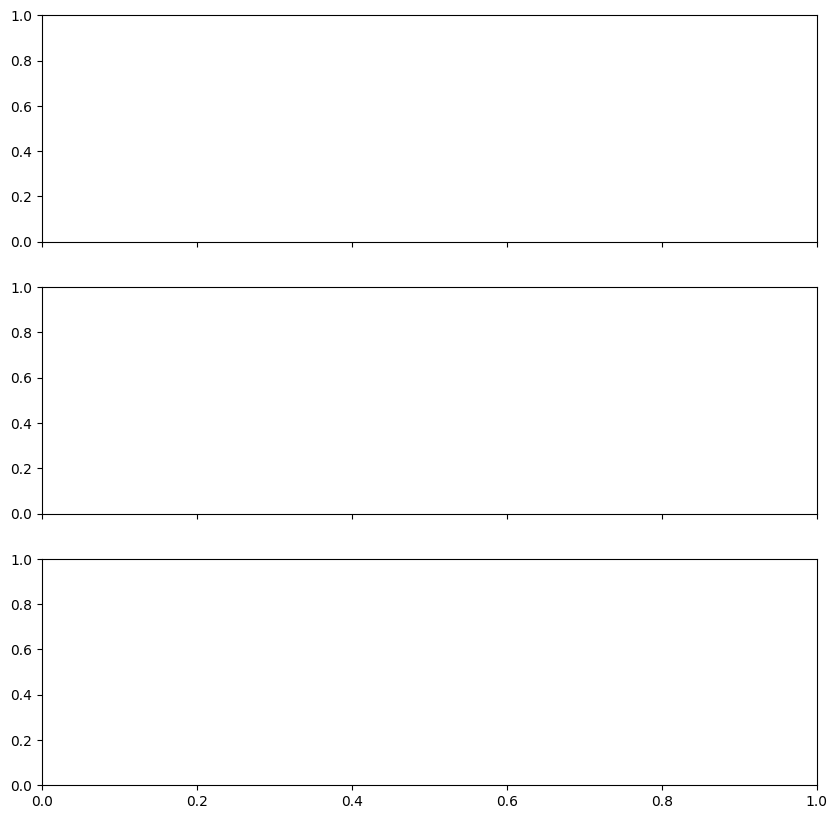

In [42]:
labels = [
    "pH",
    "Penicillin concentration (g/L)",
    "DO concentration (mg/L)"
]

# 1. Create a figure with three subplots.

fig, axs = plt.subplots(
    3, 1,
    figsize=(10, 10),
    sharex=True
)

print("Number of axes:", len(axs))

# 2. Display the empty figure to verify the subplot layout.

plt.show()

## Plot the true values and model predictions

True values: (100, 3)
Baseline LSTM: (100, 3)
LSTM + MHE: (100, 3)


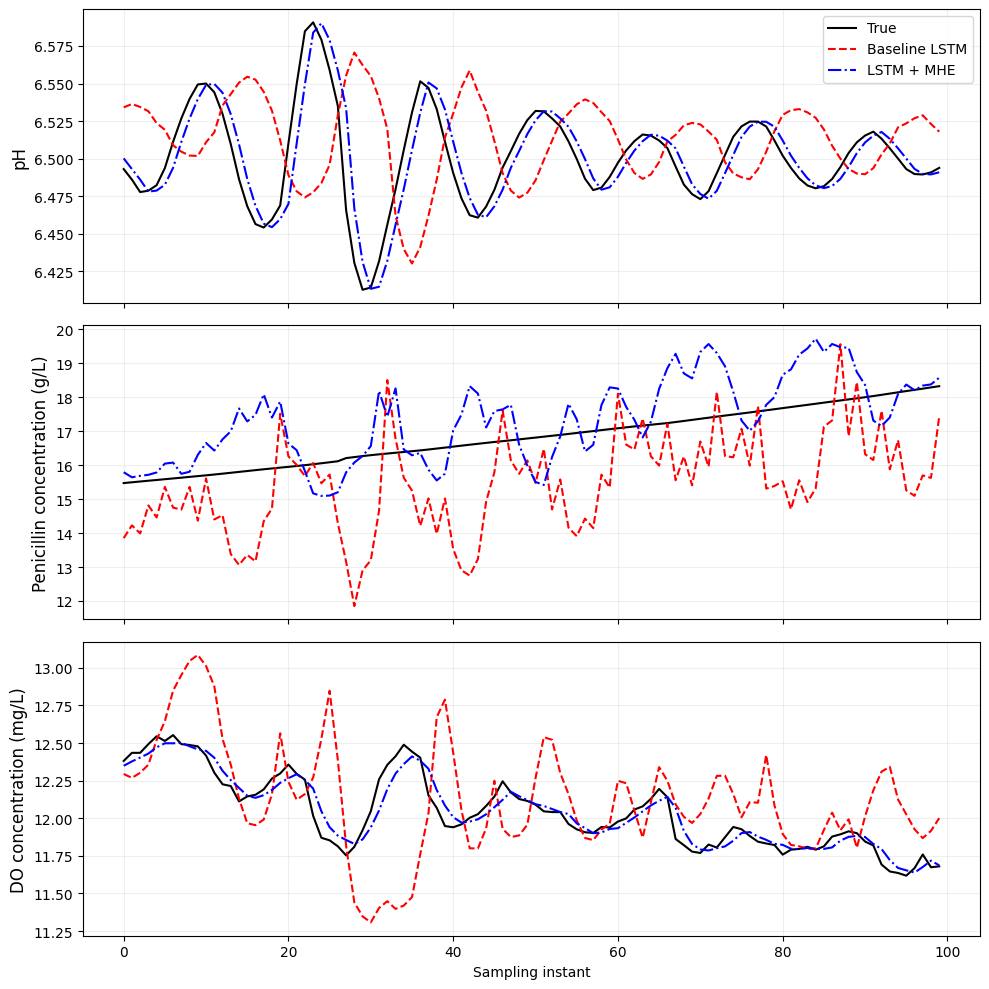

In [43]:
y_true = np.column_stack([
    ph_true_mhe_lag[start:end],
    penicillin_true_mhe_lag[start:end],
    do2_true_mhe_lag[start:end]
])

y_lstm = y_pred_np[start:end]

y_mhe = np.column_stack([
    ph_pred_mhe[start:end],
    penicillin_pred_mhe[start:end],
    do2_pred_mhe[start:end]
])

print("True values:", y_true.shape)
print("Baseline LSTM:", y_lstm.shape)
print("LSTM + MHE:", y_mhe.shape)


# 2. Plot the model predictions.

labels = [
    "pH",
    "Penicillin concentration (g/L)",
    "DO concentration (mg/L)"
]

fig, axs = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

for i, label in enumerate(labels):
    axs[i].plot(y_true[:, i], color="black", label="True")
    axs[i].plot(y_lstm[:, i], "r--", label="Baseline LSTM")
    axs[i].plot(y_mhe[:, i], "b-.", label="LSTM + MHE")

    axs[i].set_ylabel(label, fontsize=12)
    axs[i].grid(alpha=0.2)

axs[2].set_xlabel("Sampling instant")
axs[0].legend(loc="upper right")

plt.tight_layout()
plt.show()

## Calculate & Plot the residual errors for both models

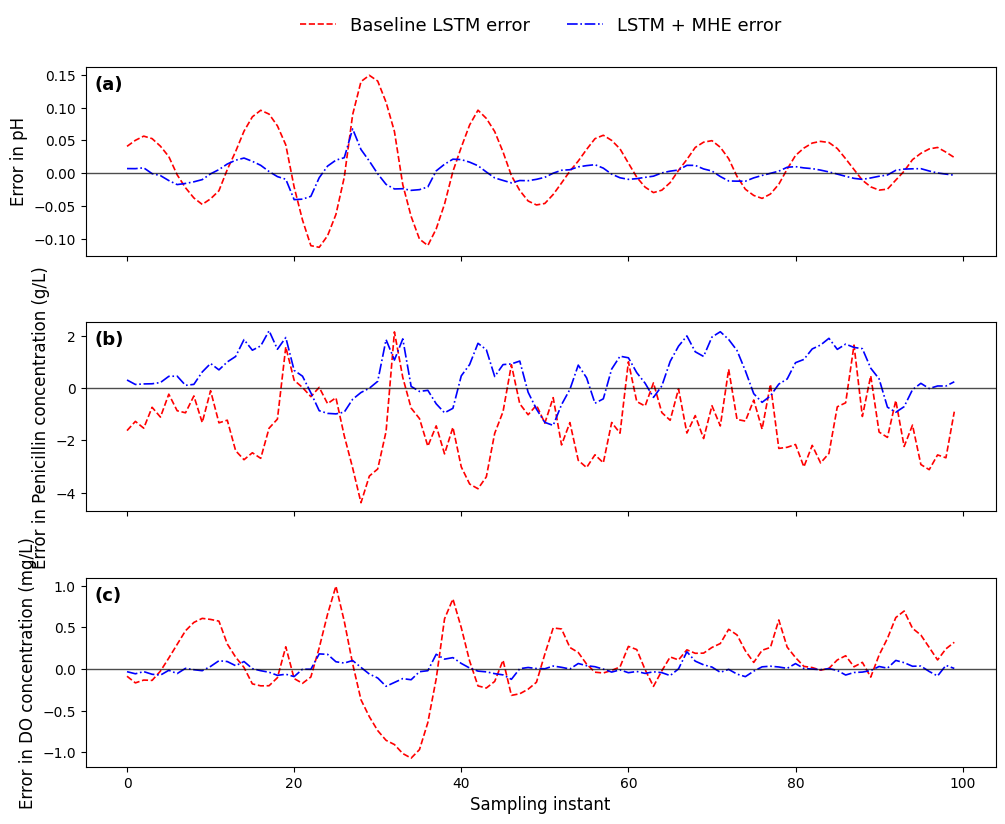

In [44]:
err_lstm = y_lstm - y_true
err_mhe = y_mhe - y_true

# Plot the residual errors.

fig, axs = plt.subplots(
    3, 1,
    figsize=(10, 10),
    sharex=True
)

error_labels = [
    "pH",
    "Penicillin concentration (g/L)",
    "DO concentration (mg/L)"
]

for i, label in enumerate(error_labels):

    axs[i].plot(
        err_lstm[:, i],
        linestyle="--",
        color="red",
        linewidth=1.2,
        label="Baseline LSTM error"
    )

    axs[i].plot(
        err_mhe[:, i],
        linestyle="-.",
        color="blue",
        linewidth=1.2,
        label="LSTM + MHE error"
    )

    axs[i].axhline(
        0,
        color="black",
        linewidth=1.0,
        alpha=0.7
    )

    axs[i].set_ylabel(
        f"Error in {label}",
        fontsize=12
    )

    axs[i].tick_params(axis="both", labelsize=10)

    axs[i].text(
        0.01, 0.88,
        f"({chr(97 + i)})",
        transform=axs[i].transAxes,
        fontsize=13,
        fontweight="bold"
    )

# Configure the residual plot layout.

axs[2].set_xlabel("Sampling instant", fontsize=12)

axs[0].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.35),
    ncol=2,
    fontsize=13,
    frameon=False
)

plt.subplots_adjust(
    left=0.08,
    right=0.99,
    top=0.85,
    bottom=0.15,
    hspace=0.35
)

plt.show()

## Comparison Table

In [45]:
# Collect MHE metrics directly from the variables already calculated
mhe_metrics = {
    'pH': {
        'R²': r2_ph_mhe,
        'RMSE': rmse_ph_mhe,
        'MAE': mae_ph_mhe
    },
    'Penicillin (g/L)': {
        'R²': r2_penicillin_mhe,
        'RMSE': rmse_penicillin_mhe,
        'MAE': mae_penicillin_mhe
    },
    'DO₂ (mg/L)': {
        'R²': r2_do2_mhe,
        'RMSE': rmse_do2_mhe,
        'MAE': mae_do2_mhe
    }
}

# Collect baseline LSTM metrics directly from the dictionaries already calculated
lstm_metrics = {
    'pH': {
        'R²': r2_vals['pH'],
        'RMSE': rmse_vals['pH'],
        'MAE': mae_vals['pH']
    },
    'Penicillin (g/L)': {
        'R²': r2_vals['Penicillin (g/L)'],
        'RMSE': rmse_vals['Penicillin (g/L)'],
        'MAE': mae_vals['Penicillin (g/L)']
    },
    'DO₂ (mg/L)': {
        'R²': r2_vals['DO₂ (mg/L)'],
        'RMSE': rmse_vals['DO₂ (mg/L)'],
        'MAE': mae_vals['DO₂ (mg/L)']
    }
}

# Create comparison DataFrame
comparison = pd.DataFrame({
    'LSTM R²': {state: values['R²'] for state, values in lstm_metrics.items()},
    'MHE R²': {state: values['R²'] for state, values in mhe_metrics.items()},
    'LSTM RMSE': {state: values['RMSE'] for state, values in lstm_metrics.items()},
    'MHE RMSE': {state: values['RMSE'] for state, values in mhe_metrics.items()},
    'LSTM MAE': {state: values['MAE'] for state, values in lstm_metrics.items()},
    'MHE MAE': {state: values['MAE'] for state, values in mhe_metrics.items()}
})

# Display the comparison
display(comparison.round(4))

,LSTM R²,MHE R²,LSTM RMSE,MHE RMSE,LSTM MAE,MHE MAE
pH,0.7810,0.8188,0.0276,0.0256,0.0135,0.0079
Penicillin (g/L),0.6507,0.7658,3.7648,2.9763,2.9696,2.2676
DO₂ (mg/L),0.9084,0.9497,0.5561,0.4143,0.2551,0.0855
